In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
torch.manual_seed(42)
X = torch.linspace(-2, 2, 300).reshape(-1,1)
y = 3 * X + 2 + 0.7 * torch.rand_like(X)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    random_state=42,
    test_size=0.20,
)

In [4]:
class RegressionNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1,8),
            nn.ReLU(),
            nn.Linear(8,1)
        )

    def forward(self, x):
        return self.network(x)

In [5]:
model = RegressionNet()

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr = 0.01
)

epochs = 100
train_losses = []
test_losses = []

In [6]:
for epoch in range(epochs):
    model.train()

    predictions = model(X_train)
    loss = criterion(predictions, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    train_losses.append(loss.item())

    model.eval()

    with torch.no_grad():
        test_predictions = model(X_test)
        test_loss = criterion(test_predictions, y_test)

    test_losses.append(test_loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | TrainLoss {loss.item():.4f} | TestLoss {test_loss.item():.4f}")

Epoch [10/100] | TrainLoss 9.9840 | TestLoss 9.6730
Epoch [20/100] | TrainLoss 3.2528 | TestLoss 3.0396
Epoch [30/100] | TrainLoss 1.0503 | TestLoss 1.0114
Epoch [40/100] | TrainLoss 0.4667 | TestLoss 0.4688
Epoch [50/100] | TrainLoss 0.2727 | TestLoss 0.2882
Epoch [60/100] | TrainLoss 0.1972 | TestLoss 0.2178
Epoch [70/100] | TrainLoss 0.1598 | TestLoss 0.1820
Epoch [80/100] | TrainLoss 0.1368 | TestLoss 0.1583
Epoch [90/100] | TrainLoss 0.1201 | TestLoss 0.1400
Epoch [100/100] | TrainLoss 0.1071 | TestLoss 0.1258


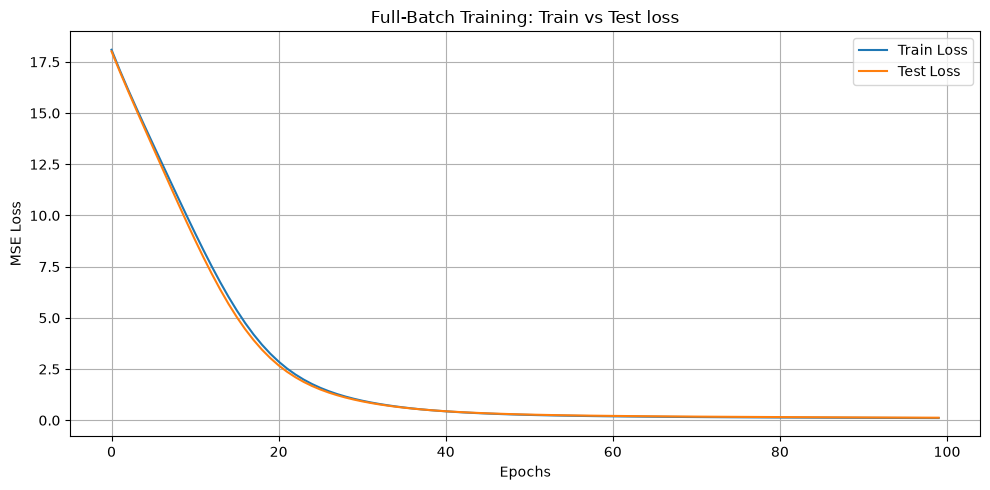

In [7]:
plt.figure(figsize=(10,5))

plt.plot(train_losses, label = "Train Loss")
plt.plot(test_losses, label = "Test Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Full-Batch Training: Train vs Test loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
print(f"Final train loss: {train_losses[-1]:.4f}")
print(f"Final test loss:  {test_losses[-1]:.4f}")

Final train loss: 0.1071
Final test loss:  0.1258
